# Pipeline: stationarity → ARDL

**Question.** Is there a stable long-run link between quarterly inflation and the nominal interest rate that can be estimated in a single equation?

**Data.** Quarterly inflation `Dp` and interest rate `R` (`exemples/ARDL/data/interest_inflation.csv`), 1972Q2–1998Q4 (107 observations).

**Why this order of steps.**

1. **Integration order** decides which estimators are valid. ARDL bounds testing is designed for regressors that are **I(0), I(1), or a mix** — not I(2). Unit-root evidence must come *before* lag selection and bounds tests.
2. **Single-equation ARDL** is appropriate when one equation is of primary interest (here: inflation given the rate). A VAR/VECM would treat both variables symmetrically and would require a full system; with *k* = 1 endogenous regressor and a clear dependent variable, ARDL is the natural reduced form.
3. **Lag length** is chosen by information criteria on the levels ARDL, then the **bounds F-test** assesses level cointegration without pre-testing every series into a rigid I(1)/I(1) Johansen setup.

Critical values for sequential ADF: MacKinnon (2010) for τ; Dickey–Fuller (1981) for Φ. Bounds: Pesaran, Shin & Smith (2001); finite-sample Narayan (2005) tables when available in makystats.

Requires **makystats ≥ 0.1.5**.


## 1. Setup


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from makystats import adf, adf_sequential, kpss, ardl, select_ardl_order

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.titlesize"] = 12

## 2. Data

Inflation `Dp` is the quarterly rate of price change; `R` is the nominal interest rate on the same quarterly grid. Both series are used in **levels** for the ARDL (the bounds procedure is a levels test).


In [2]:
raw = pd.read_csv("../ARDL/data/interest_inflation.csv")
raw.index = pd.PeriodIndex.from_fields(
    year=raw["year"].astype(int),
    quarter=raw["quarter"].astype(int),
    freq="Q",
)
y = raw["Dp"].astype(float)   # dependent: inflation
x = raw[["R"]].astype(float)  # regressor: interest rate

print(f"Sample: {y.index[0]} → {y.index[-1]}  (n = {len(y)})")
print(y.describe().to_frame("Dp").join(x["R"].describe().to_frame("R")).T.round(4))

Sample: 1972Q2 → 1998Q4  (n = 107)
    count    mean     std     min     25%     50%     75%    max
Dp  107.0  0.0084  0.0189 -0.0292 -0.0043  0.0087  0.0239  0.043
R   107.0  0.0746  0.0165  0.0380  0.0605  0.0740  0.0860  0.113


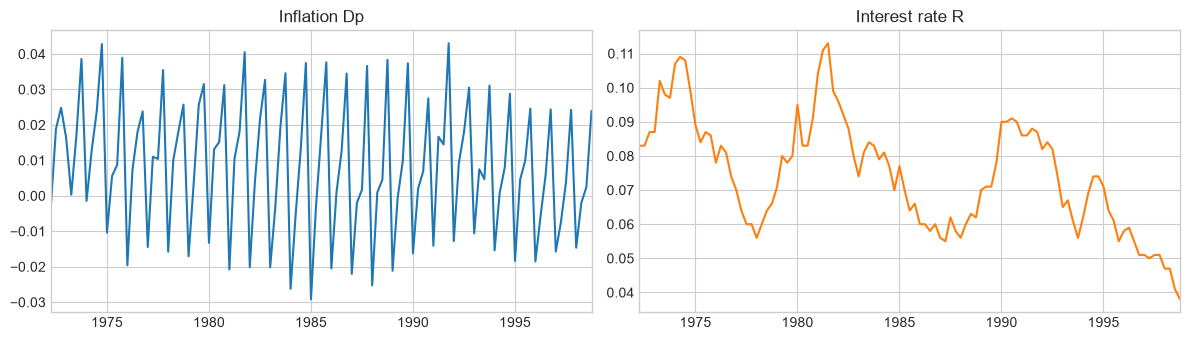

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
y.plot(ax=axes[0], title="Inflation Dp", color="C0", legend=False)
x["R"].plot(ax=axes[1], title="Interest rate R", color="C1", legend=False)
for ax in axes:
    ax.set_xlabel("")
fig.tight_layout()
plt.show()


## 3. Integration order

We combine:

- **`adf_sequential`**: classical DF decision tree (Model 3 → Φ tests → Model 2 → …), so the deterministic specification is data-driven rather than assumed.
- **`kpss`**: null of stationarity (complementary to ADF’s unit-root null).
- **ADF on first differences**: a series that is I(1) in levels should reject the unit root after one difference (and must not look I(2)).

Interpretation is joint: we do not rely on a single p-value in isolation.


In [5]:
def integration_report(series, name, alpha=0.05):
    seq = adf_sequential(series, alpha=alpha)
    k_c = kpss(series, regression="c")
    d1 = series.diff().dropna()
    adf_d = adf(d1, regression="c", autolag="AIC")
    print("=" * 72)
    print(name)
    print("=" * 72)
    print(seq.summary())
    print()
    print(f"KPSS (null: level-stationary, c): stat={k_c.statistic:.4f}, p≈{k_c.pvalue:.4f}")
    print(f"ADF on Δ{name} (c, AIC lags): stat={adf_d.statistic:.4f}, p≈{adf_d.pvalue:.4g}, lags={adf_d.lags}")
    print()
    return seq

Dp
Sequential ADF (Dickey–Fuller strategy)
  alpha      : 0.05
  lags (p)   : 3
  nobs       : 103
  final model: n
  conclusion : I(1) without drift (random walk)
  path:
    (1) Model 3 (const + trend): test H0: rho = 0
        t_rho: -2.65512
        pvalue: 0.255187
        reject_unit_root: False
        coef_trend: -4.9085e-05
        t_trend: -1.72888
        coef_const: 0.00658299
        t_const: 2.2307
    (2) Model 3: joint Phi3 H0: (rho, b) = (0, 0)
        phi3: 3.52511
        cv: 6.487
        critical_values: {'1%': 8.724, '5%': 6.487, '10%': 5.4684}
        reject_phi3: False
        joint: <use path[1]['joint'].summary()>
    (3) Model 3 (ii-a): joint Phi2 H0: (rho, c, b) = (0, 0, 0)
        phi2: 2.51689
        cv: 4.8774
        critical_values: {'1%': 6.4944, '5%': 4.8774, '10%': 4.158200000000001}
        reject_phi2: False
        joint: <use path[2]['joint'].summary()>
    (4) Model 3: Phi2 accepted — continue to Model 2
    (5) Model 2 (const): test H0: rho = 

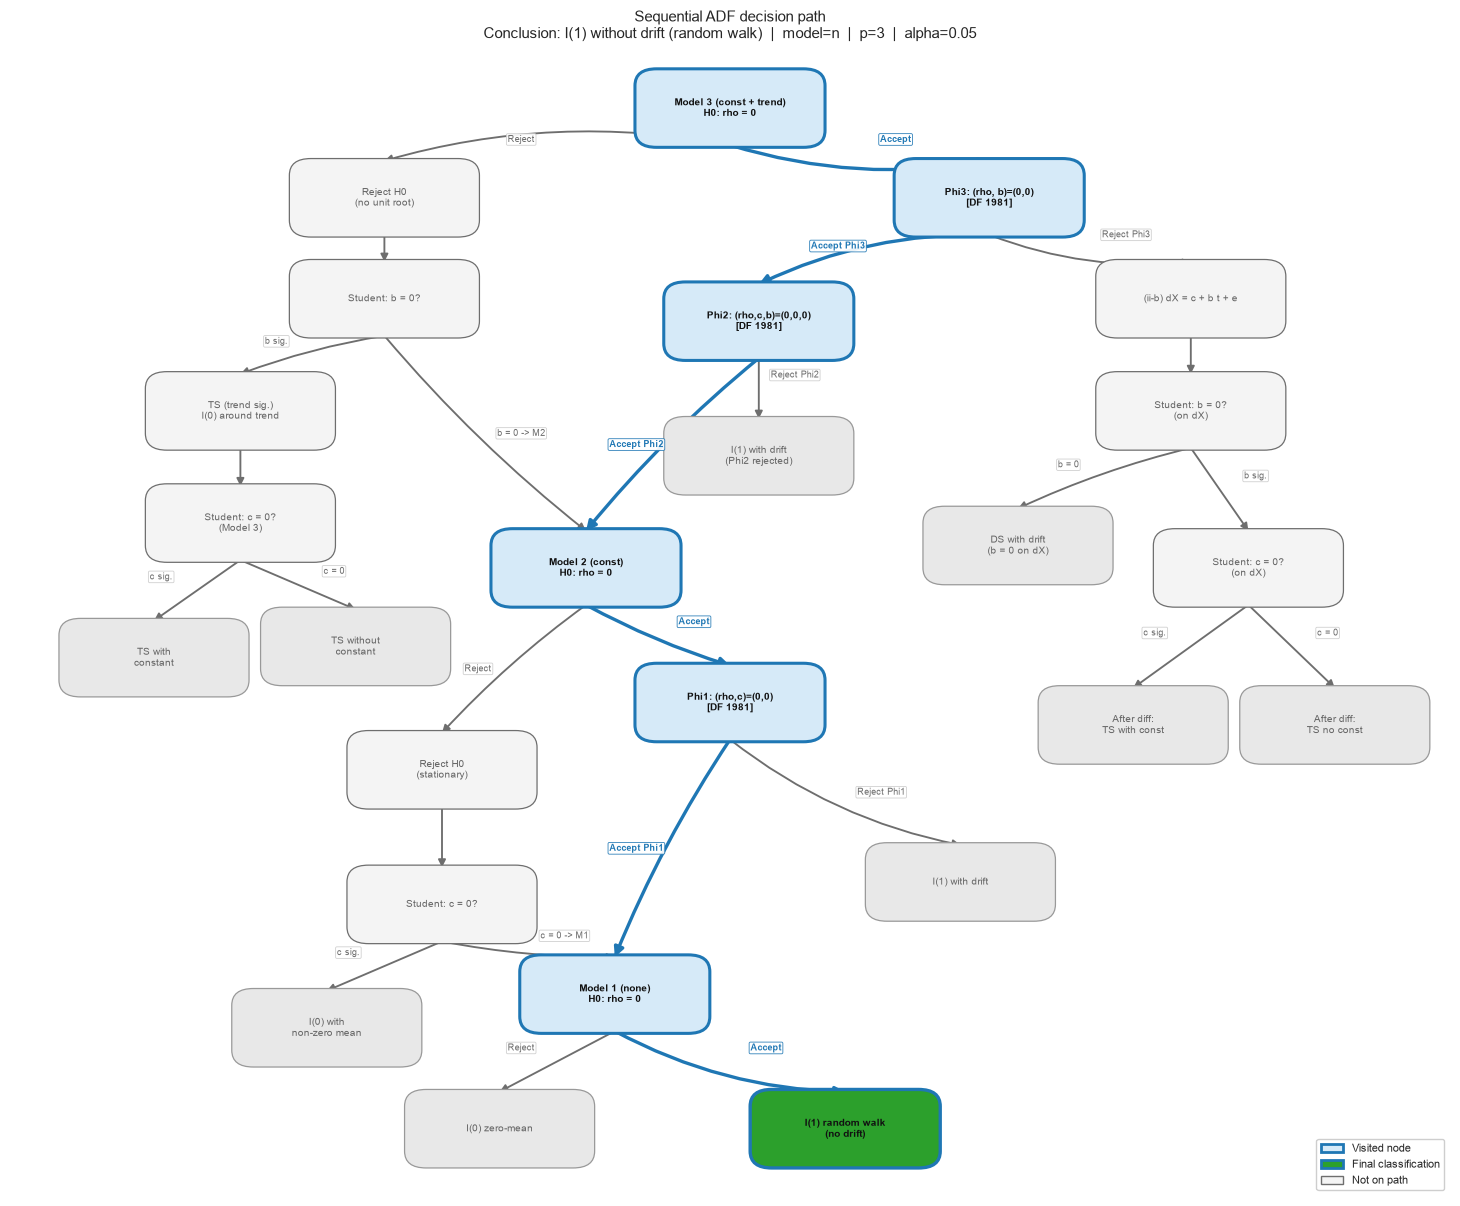

In [9]:
seq_dp = integration_report(y, "Dp")
seq_dp.plot()
plt.show()

R
Sequential ADF (Dickey–Fuller strategy)
  alpha      : 0.05
  lags (p)   : 0
  nobs       : 106
  final model: n
  conclusion : I(1) without drift (random walk)
  path:
    (1) Model 3 (const + trend): test H0: rho = 0
        t_rho: -1.92683
        pvalue: 0.640657
        reject_unit_root: False
        coef_trend: -3.89251e-05
        t_trend: -1.82964
        coef_const: 0.00748778
        t_const: 1.95158
    (2) Model 3: joint Phi3 H0: (rho, b) = (0, 0)
        phi3: 2.23943
        cv: 6.484
        critical_values: {'1%': 8.718, '5%': 6.484, '10%': 5.4668}
        reject_phi3: False
        joint: <use path[1]['joint'].summary()>
    (3) Model 3 (ii-a): joint Phi2 H0: (rho, c, b) = (0, 0, 0)
        phi2: 1.70631
        cv: 4.8748
        critical_values: {'1%': 6.4888, '5%': 4.8748000000000005, '10%': 4.1564}
        reject_phi2: False
        joint: <use path[2]['joint'].summary()>
    (4) Model 3: Phi2 accepted — continue to Model 2
    (5) Model 2 (const): test H0: rho 

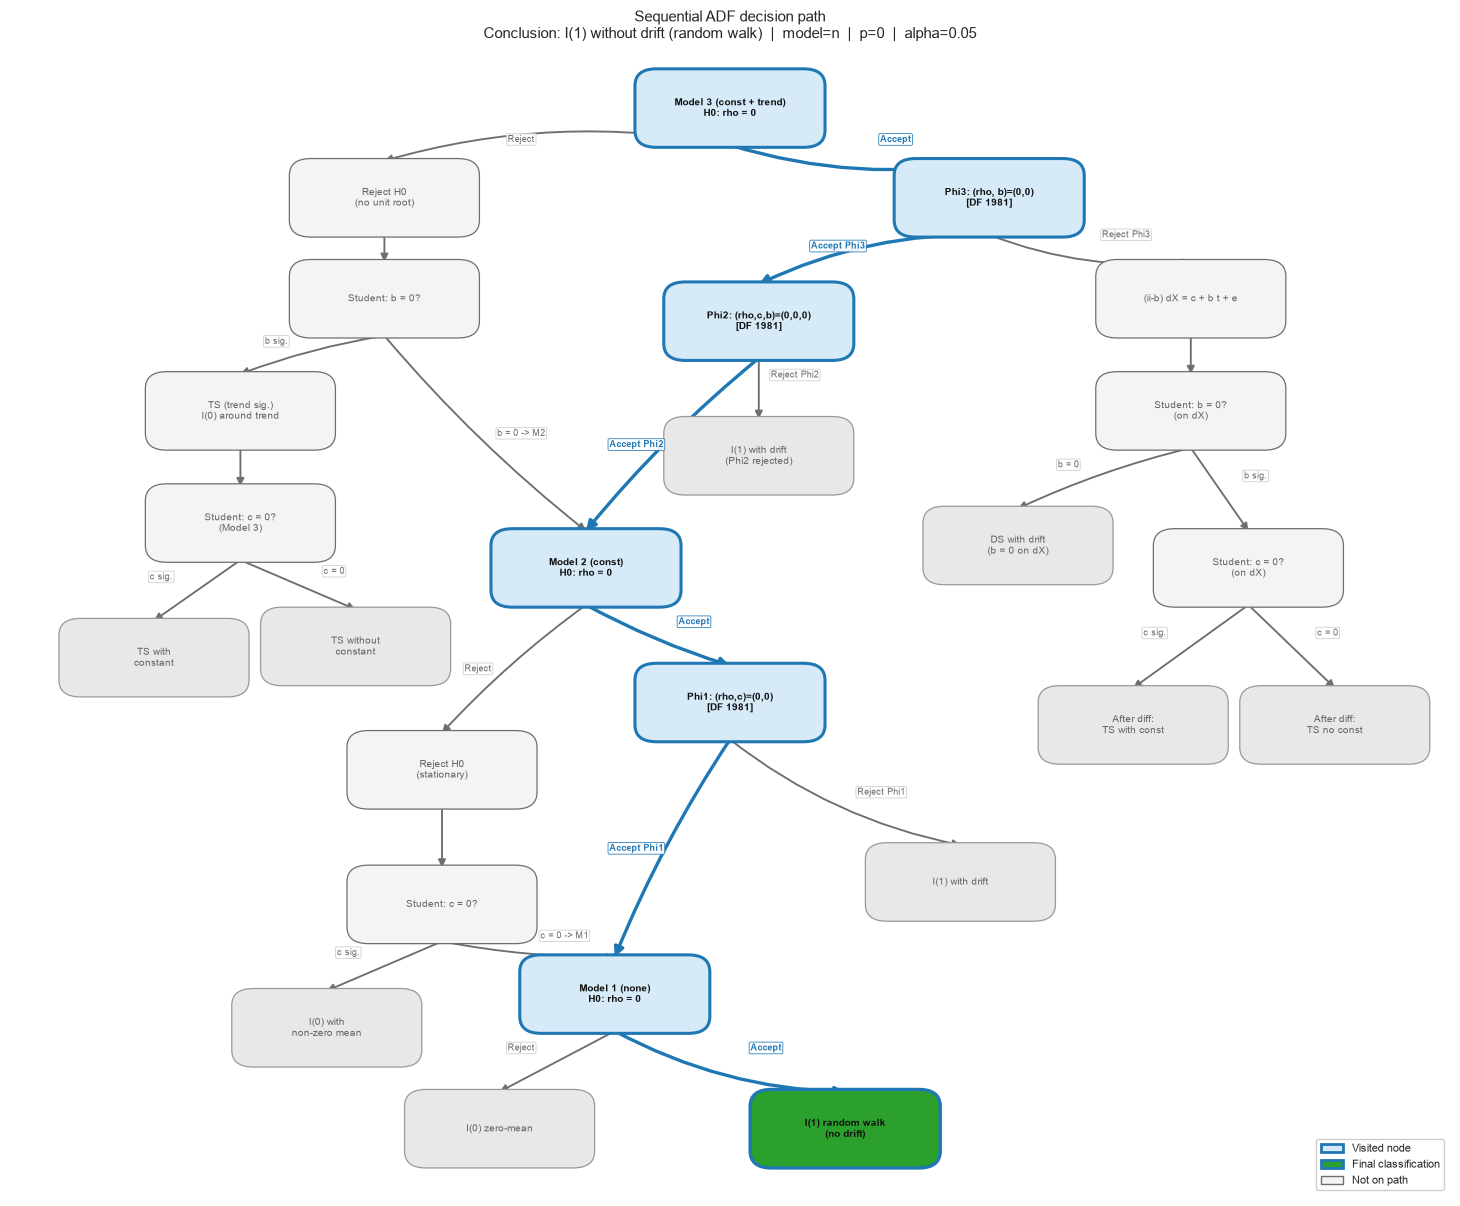

In [10]:
seq_r = integration_report(x["R"], "R")
seq_r.plot()
plt.show()

### Reading the stationarity step

On this sample the sequential ADF typically classifies **both `Dp` and `R` as I(1)** (unit root retained in levels; differences stationary). KPSS often **rejects** level-stationarity for `R` and is borderline or rejecting for `Dp`, which is consistent with I(1) behavior.

That pattern is exactly the setting the **ARDL bounds test** was built for: regressors I(0)/I(1)/mixed, dependent variable not I(2). We do **not** difference away the levels relationship a priori; we keep levels and test for a long-run equation next.

If either series had looked **I(2)**, the standard PSS bounds tables would not apply and the pipeline would stop or switch strategy.


## 4. Why ARDL (not VAR / VECM) here

| Criterion | Choice |
|-----------|--------|
| Object of interest | One equation: inflation conditional on the rate |
| Number of stochastic trends | Small system (two series); single-equation bounds are transparent |
| Pre-testing | Bounds avoid forcing a full Johansen rank decision before estimation |
| Sample size | ~100 usable observations after lags — system VECM is possible but heavier and not necessary for this question |

A **VAR in levels** or **VECM** remains valid alternative research designs; they answer a *system* question. This notebook answers a *conditional* one.


## 5. Deterministic case and lag selection

**PSS case 3** (unrestricted intercept, no trend) matches series that wander without a deterministic linear trend in the cointegrating relation — consistent with the sequential ADF paths above (no strong trend under the maintained unit-root branches).

Lag orders \((p, q_R)\) are chosen by **BIC** over a modest grid. BIC penalizes more than AIC and is preferable when the goal is a parsimonious conditional model on a moderate sample. We still inspect the top AIC rows so the ranking is not a black box.


In [11]:
# Grid: p = 0..4 lags of Dp; q_R = 0..2 lags of R; case 3; BIC ranking
order_table = select_ardl_order(
    y, x,
    maxlag=4,
    maxorder=2,
    case=3,
    ic="bic",
    verbose=False,
    refit_best=True,
)
print(order_table.head(8).to_string())
print()
print("Selected (BIC):", order_table.index[0])
print("BIC =", float(order_table["bic"].iloc[0]))
print("AIC =", float(order_table["aic"].iloc[0]))

            p     order         aic         bic        hqic          ll  n_obs  case  q_R  q
ARDL(4; 0)  4  {'R': 0} -745.667119 -729.858745 -739.264186  378.833559    103     3    0  0
ARDL(4; 1)  4  {'R': 1} -748.003689 -729.560586 -740.533601  381.001845    103     3    1  1
ARDL(4; 2)  4  {'R': 2} -746.497962 -725.420130 -737.960718  381.248981    103     3    2  2
ARDL(3; 1)  3  {'R': 1} -646.527565 -630.661219 -640.099642  329.263782    104     3    1  1
ARDL(3; 2)  3  {'R': 2} -646.637469 -628.126733 -639.138226  330.318734    104     3    2  2
ARDL(3; 0)  3  {'R': 0} -635.692548 -622.470593 -630.335945  322.846274    104     3    0  0
ARDL(2; 1)  2  {'R': 1} -564.956293 -551.686491 -559.579107  287.478146    105     3    1  1
ARDL(2; 0)  2  {'R': 0} -560.123499 -549.507658 -555.821751  284.061750    105     3    0  0

Selected (BIC): ARDL(4; 0)
BIC = -729.8587449909497
AIC = -745.6671189203275


### Lag choice — economic content

On this dataset the BIC ranking is dominated by **`ARDL(4, 0)`**: four lags of inflation (a full year at quarterly frequency) and **only the contemporaneous interest rate**. That is not an arbitrary “tutorial (2,2)”:

- Quarterly inflation is persistent; lag 4 often matters for seasonal and annual dynamics in the conditional mean.
- Extra lags of `R` improve AIC only marginally and are **BIC-dominated**.
- Contemporaneous `R` is admissible in a conditional model when the rate is treated as weakly exogenous for the parameters of interest (a maintained assumption of single-equation ARDL; it can be discussed further in a system framework).

We proceed with **`ARDL(4, 0)`, case 3**.


## 6. Estimate the levels ARDL


                              ARDL Model Results                              
Dep. Variable: Dp                                        No. Observations: 103
Model:         ARDL(4, 0)                            Log Likelihood:   378.834
Method:        OLS (conditional)                  S.D. of innov.:   0.00614537
Case (PSS):    3 (Constant)                         AIC:              -745.667
Date:          Wed, 04 Nov 2026                     BIC:              -729.859
Time:          17:40:33                             HQIC:             -739.264
            coef    std err          t      P>|t|     [0.025     0.975]
const    -0.0052     0.0030    -1.7481     0.0836    -0.0111     0.0007
Dp.L1    -0.1638     0.0556    -2.9466     0.0040    -0.2741    -0.0535
Dp.L2    -0.1591     0.0563    -2.8269     0.0057    -0.2708    -0.0474
Dp.L3    -0.1584     0.0566    -2.7964     0.0062    -0.2708    -0.0460
Dp.L4     0.8011     0.0556    14.4130     0.0000     0.6908     0.9115
R.L0      0.140

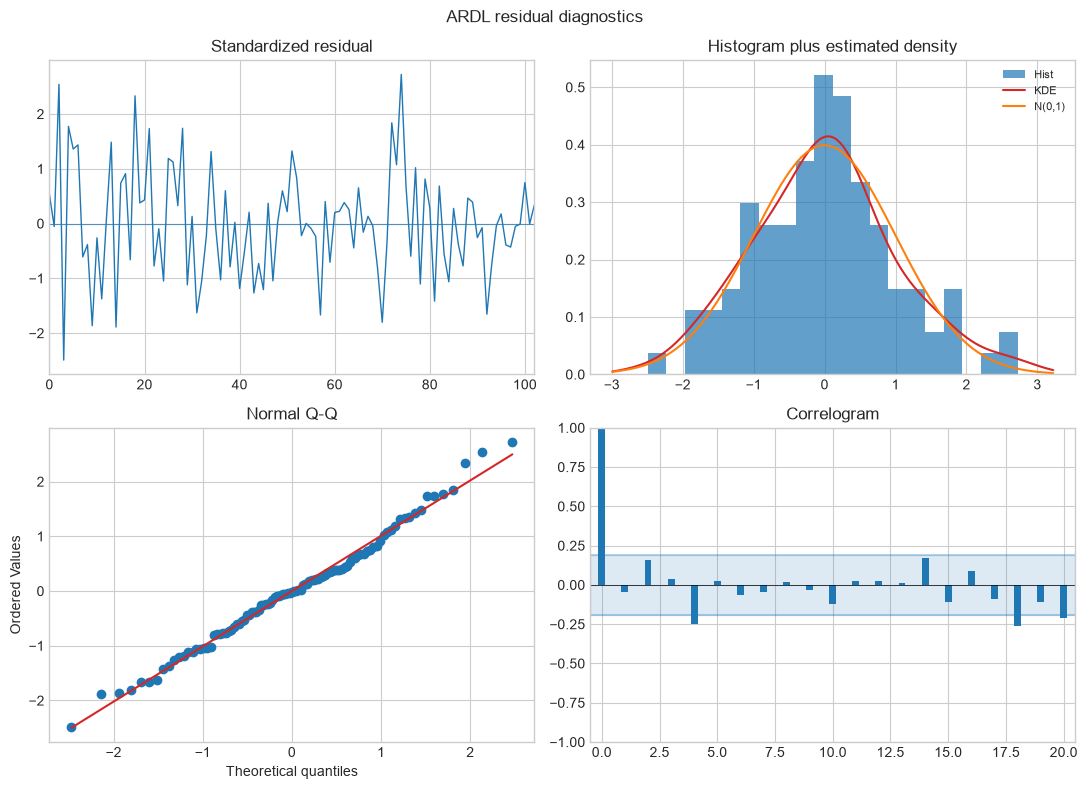

In [15]:
model = ardl(y, x, lags=4, order={"R": 0}, case=3).fit(verbose=False)
print(model.summary())
model.plot_diagnostics()
plt.show()

### Residual diagnostics (from the summary)

Look for:

- **Ljung–Box** on residuals: absence of remaining linear autocorrelation at short lags.
- **ARCH-LM**: ARDL is a conditional *mean* model; mild ARCH does not invalidate OLS consistency under standard regularity but affects efficiency and interval accuracy.
- **Jarque–Bera**: normality is convenient, not required for large-sample inference on the mean parameters.

If LB failed badly, one would return to lag selection (higher `p` or `q`) before interpreting long-run coefficients.


## 7. Bounds test for level relationship

The PSS **F-test** on the lagged levels in the UECM form tests the joint null of **no long-run level relationship**. Decision rules:

- F below the **I(0) bound** → no level relationship.
- F above the **I(1) bound** → level relationship (cointegration in the PSS sense).
- **Between the bounds** → inconclusive at that significance level.

We report both asymptotic PSS and Narayan finite-sample bounds when the package supplies them.


In [16]:
model.summary_bounds()

                       Bounds test (Pesaran / Narayan)                        
case=3 (Constant)    k=1    n=103    F=5.557189
t-stat (y.L1) = -3.398085
restrictions (q) = 2

Pesaran, Shin & Smith (2001) — asymptotic
          I(0)       I(1)     F-stat              Décision
1%      6.8610     7.7820     5.5572  Pas de cointégration
5%      4.9230     5.7220     5.5572     Zone d'indécision
10%     4.0440     4.7770     5.5572         Cointégration

Narayan (2005) — finite sample
          I(0)       I(1)     F-stat              Décision
1%      7.0950     8.2600     5.5572  Pas de cointégration
5%      5.0600     5.9300     5.5572     Zone d'indécision
10%     4.1350     4.8950     5.5572         Cointégration

Synthèse (5%) : zone d'indecision (entre les bornes I(0) et I(1))


### Honest reading of the bounds outcome

On this classic sample the F-statistic often falls in the **inconclusive zone at 5%** while clearing the **10% I(1) bound**. That is a real feature of the data and sample size, not something to paper over:

- At **10%**, evidence leans toward a level relationship.
- At **5%**, the test does not settle the question by itself.

We therefore show the **long-run multipliers and ECM** as *descriptive conditional dynamics under case 3*, and we flag that a stricter 5% researcher might stop at “inconclusive” or seek more data / a system estimator. Scientific honesty here matters more than forcing a binary “cointegrated / not” slogan.


## 8. Long-run multipliers and error-correction form


In [23]:
model.summary_uecm()
print()
print()
ecm = model.ecm()
print("Restricted ECM table:")
print(model.summary_ecm())
print()
print("Half-life (periods, approx. log(1/2)/log(1+α) when |1+α|<1):", round(ecm["half_life"], 3))
print(ecm["interpretation"])

                              UECM Model Results                              
Dep. Variable: D.Dp                                      No. Observations: 103
Model:         UECM(4, …)                            Log Likelihood:   378.834
Method:        OLS (reparam. ARDL)                  AIC:              -745.667
Case (PSS):    3 (Constant)                         BIC:              -729.859
              coef    std err          t      P>|t|     [0.025     0.975]
const      -0.0052     0.0030    -1.7481     0.0836    -0.0111     0.0007
Dp.L1      -0.6801     0.2002    -3.3981     0.0010    -1.0775    -0.2828
D.Dp.L1    -0.4836     0.1527    -3.1665     0.0021    -0.7868    -0.1805
D.Dp.L2    -0.6427     0.1043    -6.1597     0.0000    -0.8499    -0.4356
D.Dp.L3    -0.8011     0.0556   -14.4130     0.0000    -0.9115    -0.6908
R.L1        0.1409     0.0506     2.7819     0.0065     0.0403     0.2414
D.R.L0      0.1409     0.0506     2.7819     0.0065     0.0403     0.2414

Long run (mu

### Economic interpretation (cautious)

- The **long-run coefficient on `R`** is positive in this specification: higher nominal rates line up with higher inflation in the long-run solution — the direction predicted by a simple Fisher-type link, without claiming structural identification.
- The **adjustment coefficient** on the lagged equilibrium error is negative when a level relationship is entertained, which is the stable error-correction direction.
- Because the bounds test is borderline at 5%, treat magnitudes as **conditional on case 3 and ARDL(4,0)**, not as structural deep parameters.

Weak exogeneity of `R` is assumed, not tested here; a VAR/VECM with exogeneity tests would be the next research step if that assumption is contested.


## 9. Takeaways

1. **Stationarity first** — sequential ADF + KPSS + differenced ADF justified levels ARDL (no I(2) signal).
2. **Model matches the question** — single-equation ARDL for conditional inflation dynamics; VAR/VECM reserved for system questions.
3. **BIC selected ARDL(4,0), case 3** — annual lag in inflation, contemporaneous rate; not an arbitrary default order.
4. **Bounds at 5% are inconclusive; at 10% supportive** — report both, then show long-run/ECM with explicit caveats.
5. **Pipeline is reproducible** in makystats without switching packages between unit-root tests and ARDL.

```python
from makystats import adf_sequential, kpss, select_ardl_order, ardl
seq = adf_sequential(y)
table = select_ardl_order(y, x, maxlag=4, maxorder=2, case=3, ic="bic")
model = ardl(y, x, lags=4, order={"R": 0}, case=3).fit()
model.summary_bounds()
```
